<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%A013_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%94%D0%B0%D0%BD%D0%B8%D0%BB%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Класифікація зображень гральних карт
CNN та VGG16 (Transfer Learning і Fine-tuning)

In [1]:
!pip -q install kagglehub keras-tuner

In [2]:
import os, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt
import kagglehub
keras.utils.set_random_seed(42)
print(tf.config.list_physical_devices('GPU'))
root = Path(kagglehub.dataset_download('gpiosenka/cards-image-datasetclassification'))
train_dir = next(p for p in root.rglob('train') if p.is_dir())
val_dir = next(p for p in train_dir.parent.iterdir() if p.name in ('valid','validation','val'))
test_dir = train_dir.parent / 'test'
print(train_dir, val_dir, test_dir)

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
/kaggle/input/cards-image-datasetclassification/train /kaggle/input/cards-image-datasetclassification/valid /kaggle/input/cards-image-datasetclassification/test


## 1. Аналіз даних

Кількість класів: 53


,train,valid,test
ace of clubs,120,5,5
ace of diamonds,129,5,5
ace of hearts,171,5,5
ace of spades,181,5,5
eight of clubs,138,5,5
eight of diamonds,159,5,5
eight of hearts,152,5,5
eight of spades,135,5,5
five of clubs,150,5,5
five of diamonds,138,5,5


,0
train,7624
valid,265
test,265


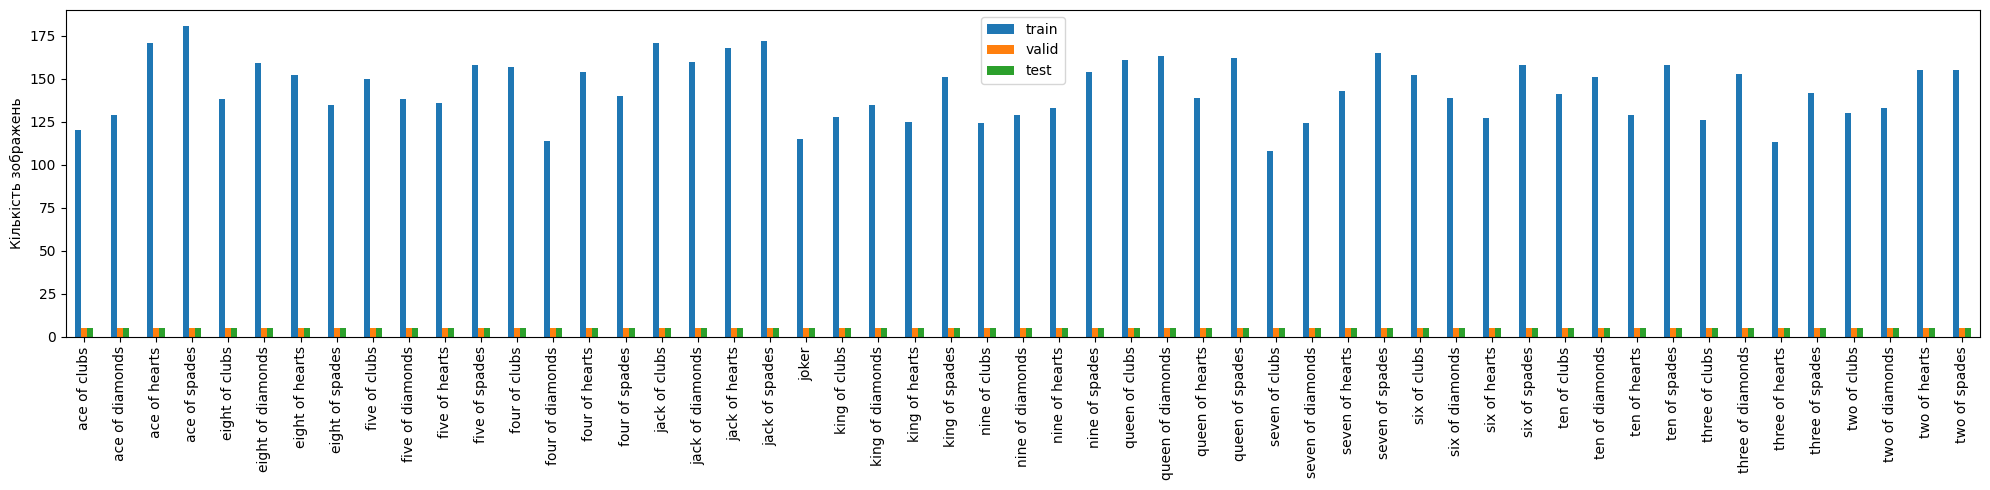

In [3]:
ext = {'.jpg','.jpeg','.png','.bmp','.gif'}
classes = sorted(p.name for p in train_dir.iterdir() if p.is_dir())
counts = pd.DataFrame({split: [sum(p.suffix.lower() in ext for p in (folder / name).rglob('*')) for name in classes] for split, folder in [('train',train_dir),('valid',val_dir),('test',test_dir)]}, index=classes)
print('Кількість класів:', len(classes))
display(counts)
display(counts.sum())
counts.plot(kind='bar', figsize=(20,5)); plt.ylabel('Кількість зображень'); plt.tight_layout(); plt.show()

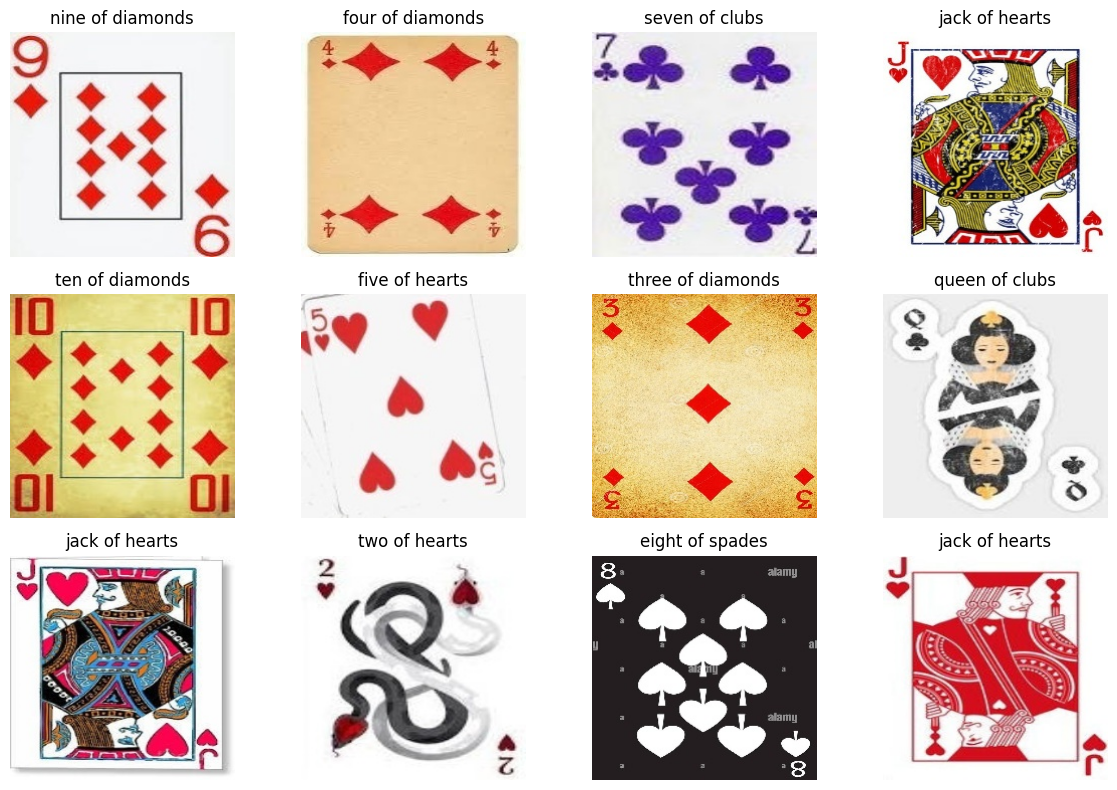

In [4]:
files = [p for p in train_dir.rglob('*') if p.suffix.lower() in ext]
plt.figure(figsize=(12,8))
for i,p in enumerate(random.sample(files,12)):
    plt.subplot(3,4,i+1); plt.imshow(keras.utils.load_img(p)); plt.title(p.parent.name); plt.axis('off')
plt.tight_layout(); plt.show()

## 2. Підготовка даних
Використовуємо готові train/valid/test. Розмір 128×128, batch 32. Аугментація тільки під час навчання. CNN використовує масштабування 1/255, VGG16 - власну передобробку ImageNet.

In [5]:
SIZE=(128,128)
BATCH=32
K=len(classes)
def dataset(folder, shuffle=False):
    return keras.utils.image_dataset_from_directory(folder, class_names=classes, image_size=SIZE, batch_size=BATCH, shuffle=shuffle, seed=42).prefetch(tf.data.AUTOTUNE)
train=dataset(train_dir,True)
valid=dataset(val_dir)
test=dataset(test_dir)
def augmentation():
    return keras.Sequential([layers.RandomRotation(0.05), layers.RandomZoom(0.1)])
def early():
    return keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

Found 7624 files belonging to 53 classes.
Found 265 files belonging to 53 classes.
Found 265 files belonging to 53 classes.


## 3. CNN та підбір параметрів
Random Search підбирає кількість фільтрів, нейронів, Dropout та швидкість навчання за val_accuracy. Тестова вибірка не використовується для підбору.

In [6]:
def build_cnn(hp):
    f=hp.Choice('filters',[32,64])
    model=keras.Sequential([layers.Input((*SIZE,3)), augmentation(), layers.Rescaling(1./255),
        layers.Conv2D(f,3,padding='same',activation='relu'),layers.MaxPooling2D(),
        layers.Conv2D(f*2,3,padding='same',activation='relu'),layers.MaxPooling2D(),
        layers.Conv2D(f*4,3,padding='same',activation='relu'),layers.MaxPooling2D(),
        layers.Flatten(),layers.Dense(hp.Choice('dense',[128,256]),activation='relu'),
        layers.Dropout(hp.Choice('dropout',[0.3,0.5])),layers.Dense(K,activation='softmax')])
    model.compile(optimizer=keras.optimizers.Adam(hp.Choice('lr',[0.001,0.0003])),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
tuner=kt.RandomSearch(build_cnn,objective='val_accuracy',max_trials=6,overwrite=True,directory='tuning',project_name='cards')
tuner.search(train,validation_data=valid,epochs=8,callbacks=[early()])
best=tuner.get_best_hyperparameters(1)[0]
print(best.values)
cnn=build_cnn(best)
cnn.summary()
h_cnn=cnn.fit(train,validation_data=valid,epochs=25,callbacks=[early()])

Trial 6 Complete [00h 01m 08s]
val_accuracy: 0.6716980934143066

Best val_accuracy So Far: 0.8226414918899536
Total elapsed time: 00h 08m 37s
{'filters': 64, 'dense': 256, 'dropout': 0.3, 'lr': 0.001}


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │    16,777,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 53)             │        13,621 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,161,909 (65.47 MB)

 Trainable params: 17,161,909 (65.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.1628 - loss: 3.2848 - val_accuracy: 0.3849 - val_loss: 1.8511
Epoch 2/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.3749 - loss: 2.2354 - val_accuracy: 0.5887 - val_loss: 1.4352
Epoch 3/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.4971 - loss: 1.8342 - val_accuracy: 0.6755 - val_loss: 1.0872
Epoch 4/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.5632 - loss: 1.5835 - val_accuracy: 0.7547 - val_loss: 0.8353
Epoch 5/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.6179 - loss: 1.3797 - val_accuracy: 0.7887 - val_loss: 0.8277
Epoch 6/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.6548 - loss: 1.2430 - val_accuracy: 0.8000 - val_loss: 0.6442
Epoch 7/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.6818 - loss: 1.1239 - val_accuracy: 0.8000 - val_loss: 0.7172
Epoch 8/25
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.7124 - loss: 1.0256 - 

## 4. VGG16: перенесення навчання та донавчання
Спочатку заморожуємо базу ImageNet, підбираємо параметри класифікатора. Потім розморожуємо останній згортковий блок і використовуємо малу швидкість навчання.

In [7]:
def build_vgg(hp):
    base=keras.applications.VGG16(weights='imagenet',include_top=False,input_shape=(*SIZE,3))
    base.trainable=False
    inputs=keras.Input((*SIZE,3))
    x=augmentation()(inputs)
    x=layers.Lambda(keras.applications.vgg16.preprocess_input)(x)
    x=base(x,training=False)
    x=layers.Flatten()(x)
    x=layers.Dense(hp.Choice('dense',[128,256]),activation='relu')(x)
    x=layers.Dropout(hp.Choice('dropout',[0.3,0.5]))(x)
    model=keras.Model(inputs,layers.Dense(K,activation='softmax')(x))
    model.compile(optimizer=keras.optimizers.Adam(hp.Choice('lr',[0.001,0.0003])),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
    return model
tuner_vgg=kt.RandomSearch(build_vgg,objective='val_accuracy',max_trials=4,overwrite=True,directory='tuning',project_name='vgg')
tuner_vgg.search(train,validation_data=valid,epochs=6,callbacks=[early()])
best_vgg=tuner_vgg.get_best_hyperparameters(1)[0]
print(best_vgg.values)
vgg=build_vgg(best_vgg)
vgg.summary()
h_vgg=vgg.fit(train,validation_data=valid,epochs=20,callbacks=[early()])
base=next(l for l in vgg.layers if isinstance(l,keras.Model) and l.name.startswith('vgg16'))
base.trainable=True
for layer in base.layers:
    layer.trainable=layer.name.startswith('block5')
vgg.compile(optimizer=keras.optimizers.Adam(1e-5),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
h_ft=vgg.fit(train,validation_data=valid,epochs=15,callbacks=[early()])

Trial 4 Complete [00h 01m 22s]
val_accuracy: 0.3056603670120239

Best val_accuracy So Far: 0.5358490347862244
Total elapsed time: 00h 05m 30s
{'dense': 256, 'dropout': 0.3, 'lr': 0.0003}


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 53)             │        13,621 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,825,717 (64.19 MB)

 Trainable params: 2,111,029 (8.05 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 14s 51ms/step - accuracy: 0.0934 - loss: 5.0520 - val_accuracy: 0.2113 - val_loss: 3.0028
Epoch 2/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - accuracy: 0.2369 - loss: 2.9908 - val_accuracy: 0.3208 - val_loss: 2.4300
Epoch 3/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.3211 - loss: 2.5384 - val_accuracy: 0.3925 - val_loss: 2.0812
Epoch 4/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.3913 - loss: 2.2323 - val_accuracy: 0.4604 - val_loss: 1.8320
Epoch 5/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.4359 - loss: 2.0147 - val_accuracy: 0.4906 - val_loss: 1.7392
Epoch 6/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 13s 53ms/step - accuracy: 0.4811 - loss: 1.8367 - val_accuracy: 0.5208 - val_loss: 1.6632
Epoch 7/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 50ms/step - accuracy: 0.5153 - loss: 1.6848 - val_accuracy: 0.5132 - val_loss: 1.6506
Epoch 8/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 12s 51ms/step - accuracy: 0.5491 - loss: 1.5296 - 

## 5. Криві навчання

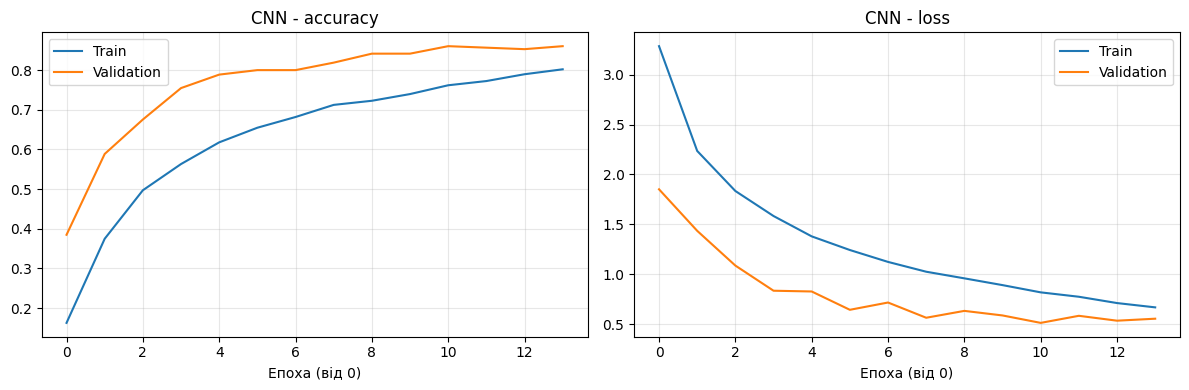

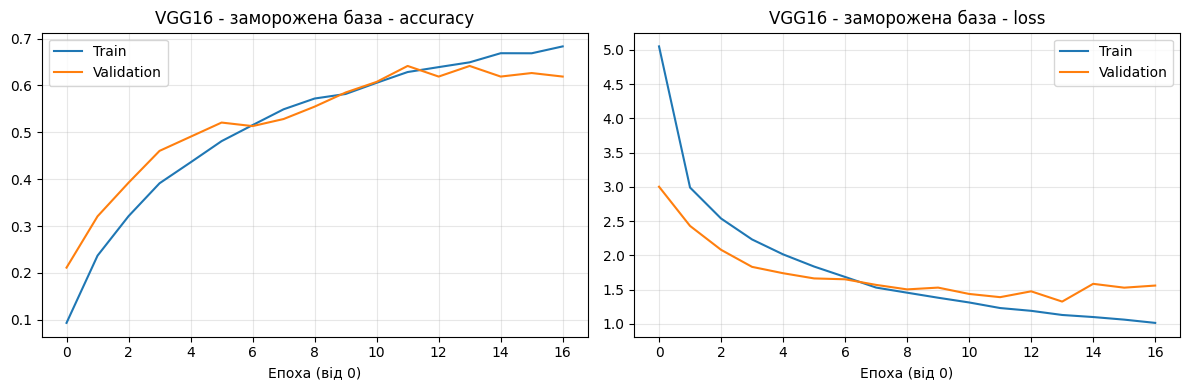

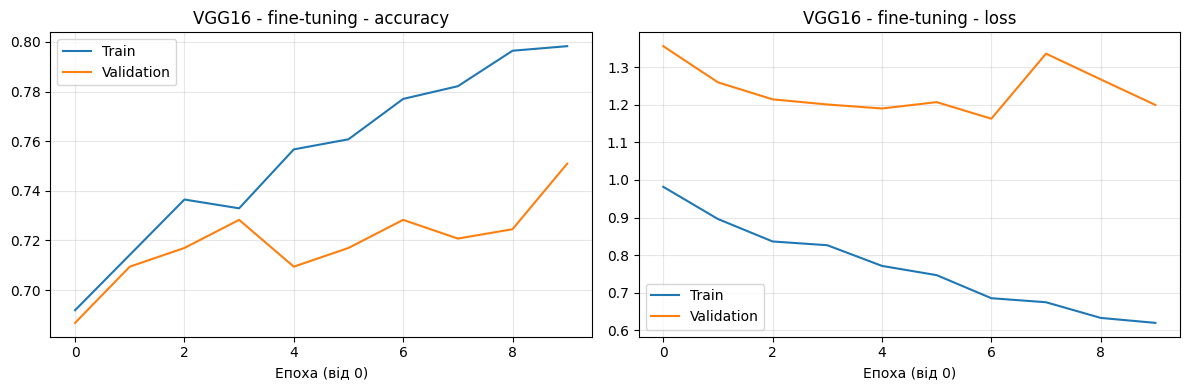

In [11]:
for title,h in [('CNN',h_cnn),('VGG16 - заморожена база',h_vgg),('VGG16 - fine-tuning',h_ft)]:
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    for a,key in zip(ax,['accuracy','loss']):
        a.plot(h.history[key],label='Train'); a.plot(h.history['val_'+key],label='Validation'); a.set_title(title+' - '+key); a.set_xlabel('Епоха (від 0)'); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 6. Оцінювання моделей на тестовій вибірці

,accuracy,loss
model,,
CNN,0.833962,0.669458
VGG16 fine-tuned,0.633962,1.894078


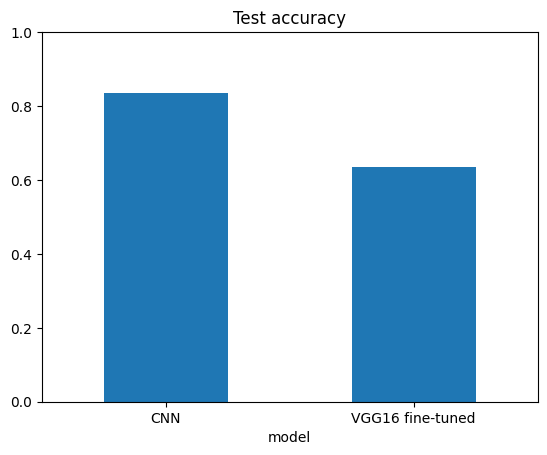

In [12]:
models={'CNN':cnn,'VGG16 fine-tuned':vgg}
results=pd.DataFrame([{'model':name,**m.evaluate(test,verbose=0,return_dict=True)} for name,m in models.items()]).set_index('model')
display(results)
results['accuracy'].plot.bar(rot=0,ylim=(0,1),title='Test accuracy'); plt.show()

## 7. Візуалізація прогнозів

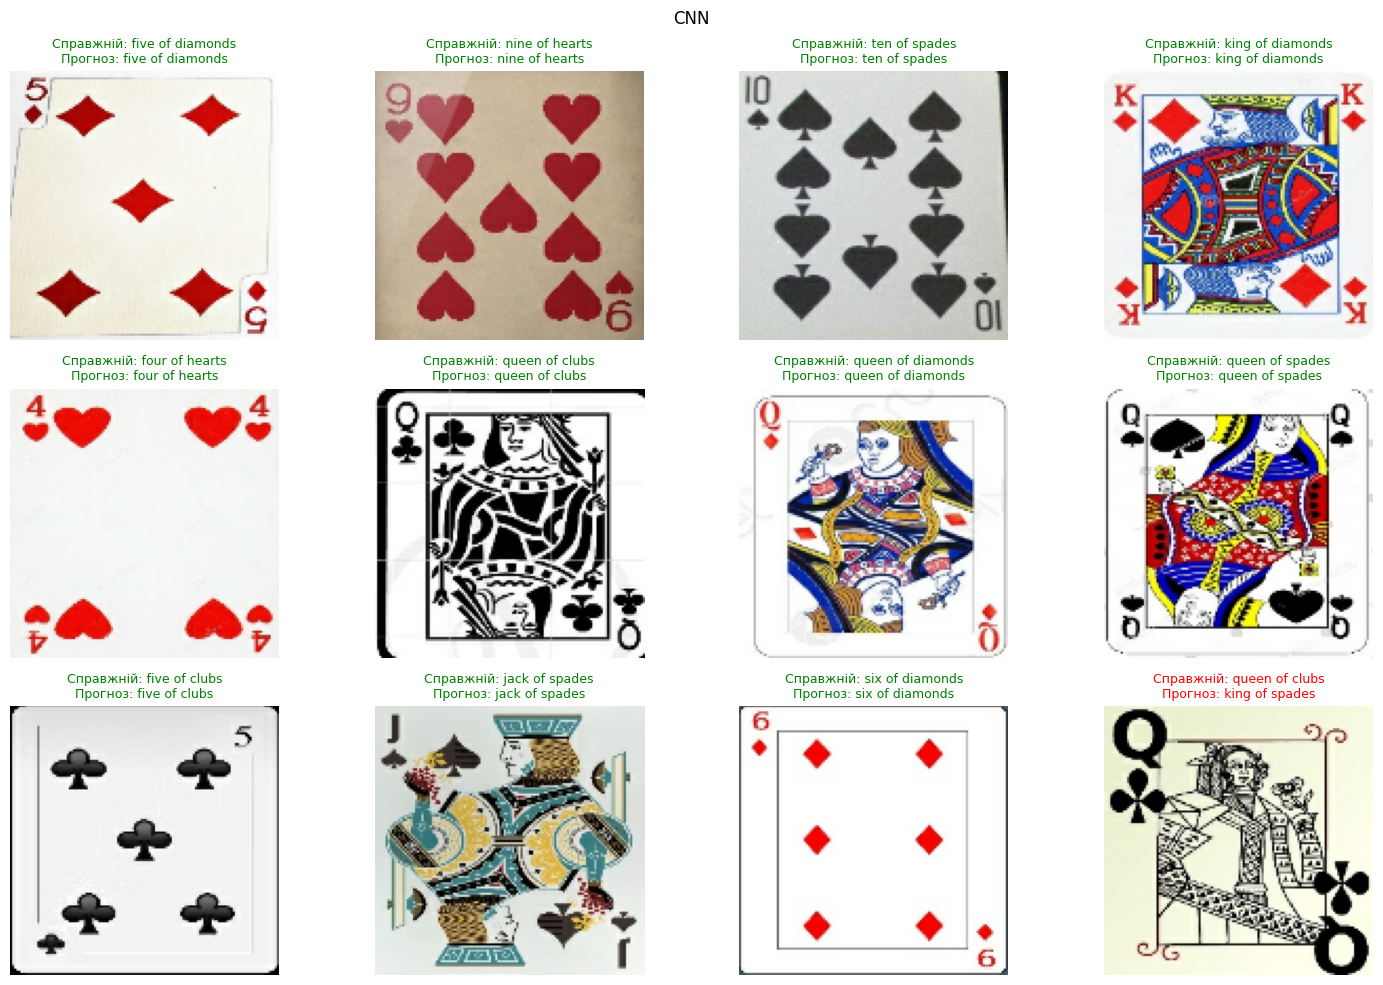

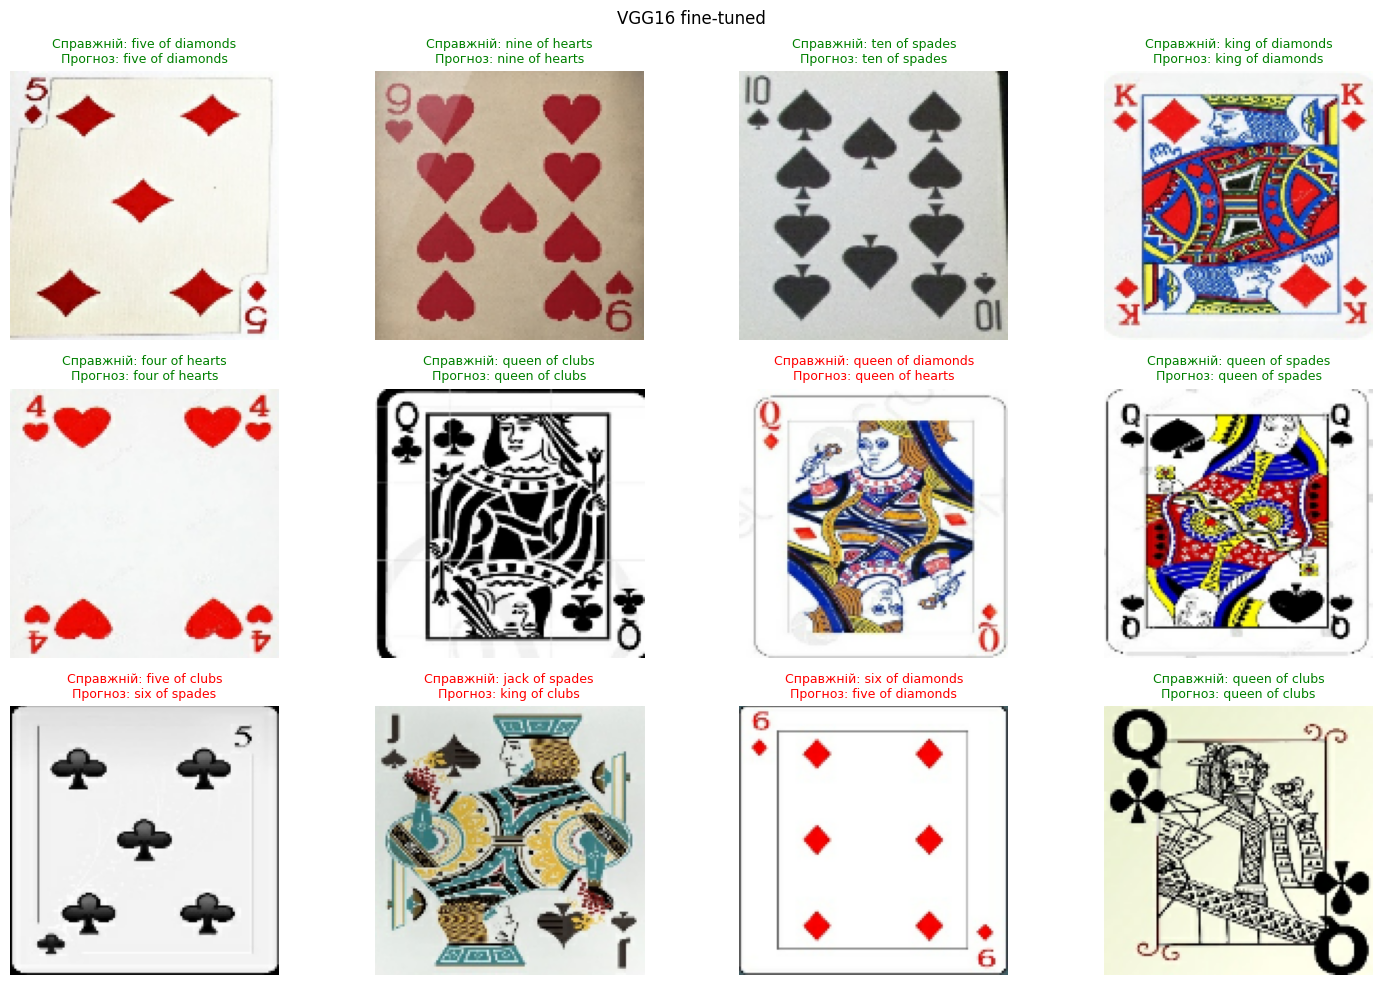

In [13]:
images,labels=next(iter(test.unbatch().shuffle(512,seed=42).batch(12)))
for name,m in models.items():
    pred=np.argmax(m.predict(images,verbose=0),axis=1)
    plt.figure(figsize=(15,10))
    for i in range(len(labels)):
        plt.subplot(3,4,i+1); plt.imshow(tf.cast(tf.clip_by_value(images[i],0,255),tf.uint8)); plt.axis('off')
        plt.title(f'Справжній: {classes[int(labels[i])]}\nПрогноз: {classes[pred[i]]}',color='green' if pred[i]==int(labels[i]) else 'red',fontsize=9)
    plt.suptitle(name); plt.tight_layout(); plt.show()

## 8. Висновки


CNN: точність 83.40%, втрати 0.6695.

VGG16 fine-tuned: точність 63.40%, втрати 1.8941.

Найвища тестова точність: CNN.

Найкращі параметри CNN: {'filters': 64, 'dense': 256, 'dropout': 0.3, 'lr': 0.001}

Найкращі параметри VGG16: {'dense': 256, 'dropout': 0.3, 'lr': 0.0003}

Максимальна validation accuracy VGG16 до fine-tuning: 64.15%; після: 75.09%.

Рання зупинка контролює validation loss та відновлює найкращі ваги. Графіки дозволяють оцінити збіжність і можливе перенавчання. Перед остаточним висновком порівняйте криві train і validation.